# Spatial rate maps: estimate firing with observation support

**Estimated time**: 20-25 minutes

**Prerequisites**: [01: getting started](01_getting_started.ipynb).

Estimate one neuron's rate map, inspect the time supporting it, and test how
smoothing changes the result. We simulate a neuron with known spatial tuning
so the plots have a reference. A rate map or segmented field from a real
recording is descriptive evidence; neither alone establishes a place cell.
This notebook runs independently and needs no data download.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from neurospatial import Environment
from neurospatial.encoding import compute_spatial_rate, detect_place_fields
from neurospatial.simulation import (
    PlaceCellModel,
    generate_poisson_spikes,
    simulate_trajectory_ou,
)

_here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
if not (_here / "_style.py").exists() and (_here / "examples" / "_style.py").exists():
    _here = _here / "examples"
if str(_here) not in sys.path:
    sys.path.insert(0, str(_here))
from _style import apply_style

apply_style(figsize=(11, 5))

## 1. Generate a recording in a known arena

Geometry covers the complete 80 × 80 cm arena, including unvisited bins.
Distances and bandwidths are centimeters; timestamps are seconds and firing
rates are spikes per second (Hz). Independent seeds control movement and spike
generation. The simulation is an illustration, not a model fit to a session.

In [2]:
edges = np.arange(0.0, 80.0 + 5.0, 5.0)
env = Environment.from_grid_mask(
    active_mask=np.ones((16, 16), dtype=bool),
    grid_edges=(edges, edges),
    name="Rate-map arena",
)
env.units, env.frame = "cm", "arena"
positions, times = simulate_trajectory_ou(
    env,
    duration=300.0,
    dt=0.01,
    speed_mean=10.0,
    speed_std=2.0,
    coherence_time=0.7,
    boundary_mode="reflect",
    speed_units="cm",
    seed=202,
)
center = np.array([55.0, 25.0])
model = PlaceCellModel(
    env,
    center=center,
    width=10.0,
    max_rate=18.0,
    baseline_rate=0.2,
    metric="euclidean",
)
spike_times = generate_poisson_spikes(
    model.firing_rate(positions, times), times, refractory_period=0.002, seed=203
)
assert np.all(np.diff(times) > 0) and np.all(np.diff(spike_times) >= 0)
assert positions.shape == (len(times), 2)
assert spike_times.min() >= times[0] and spike_times.max() <= times[-1]
print(f"Duration: {times[-1] - times[0]:.2f} s; spikes: {len(spike_times):,}")

Duration: 299.99 s; spikes: 578


Inspect raw observations before fitting. Interpolation below is only for this
gap-free display; rate estimation handles spike/position alignment internally.
With experimental data, verify common clocks, calibration, tracking dropouts,
and the intervals when spikes were recorded before interpreting a map.

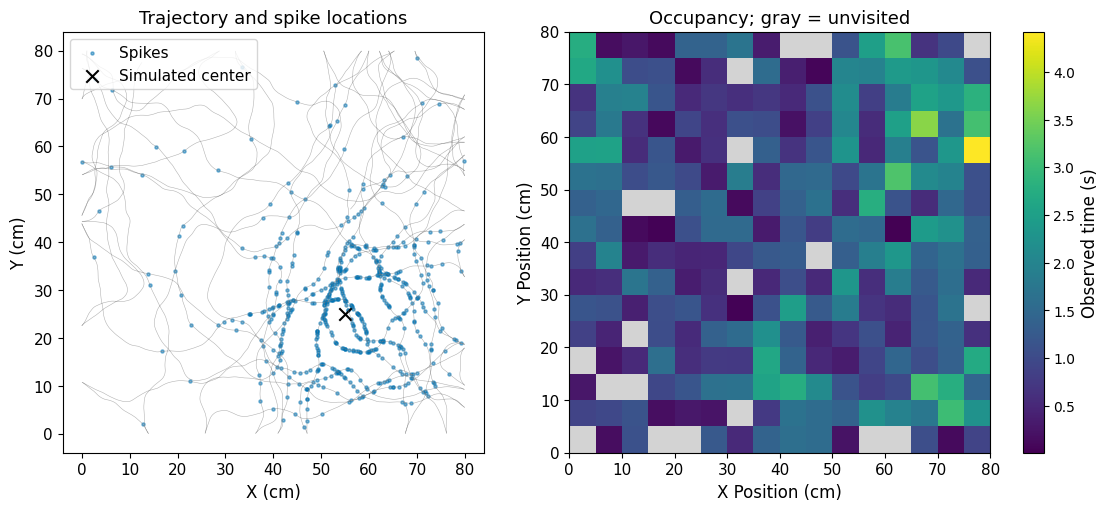

Visited bins: 236 / 256


In [3]:
spike_positions = np.column_stack(
    [np.interp(spike_times, times, positions[:, axis]) for axis in range(2)]
)
occupancy = env.occupancy(times, positions, max_gap=0.05)
fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
axes[0].plot(positions[:, 0], positions[:, 1], color="gray", lw=0.4, alpha=0.6)
axes[0].scatter(*spike_positions.T, s=5, alpha=0.5, label="Spikes")
axes[0].scatter(*center, marker="x", color="black", s=80, label="Simulated center")
axes[0].set(xlabel="X (cm)", ylabel="Y (cm)", title="Trajectory and spike locations")
axes[0].set_aspect("equal")
axes[0].legend(loc="upper left")
env.plot_field(
    np.where(occupancy > 0, occupancy, np.nan),
    ax=axes[1],
    cmap="viridis",
    nan_color="lightgray",
    colorbar_label="Observed time (s)",
)
axes[1].set_title("Occupancy; gray = unvisited")
plt.show()
print(f"Visited bins: {(occupancy > 0).sum()} / {env.n_bins}")
assert np.isclose(occupancy.sum(), times[-1] - times[0])

## 2. Estimate a map and retain its support

`compute_spatial_rate()` returns rates together with raw occupancy and analysis
settings. Diffusion KDE smooths spike counts and time over the environment
graph before taking their ratio, respecting its boundaries. `min_occupancy`
masks bins below a raw dwell-time threshold; 0.25 s is an illustrative choice.
Set `max_gap` to exclude unobserved intervals from both spikes and occupancy.

Some estimators can produce finite predictions in unvisited bins. Use
`spatial_support` when reporting measured coverage; finite values alone do not
establish observation. Keep NaN outside support rather than replacing it with
zero Hz. Zero rate in a supported bin means observed time with no counted
firing; missing support means there is insufficient observation.

In [4]:
settings = {"min_occupancy": 0.25, "max_gap": 0.05}
result = compute_spatial_rate(
    env,
    spike_times,
    times,
    positions,
    method="diffusion_kde",
    bandwidth=5.0,
    **settings,
)
supported_rate = np.where(result.spatial_support, result.firing_rate, np.nan)
raw = compute_spatial_rate(
    env, spike_times, times, positions, method="binned", bandwidth=0.0, **settings
)
print(f"Supported bins: {result.spatial_support.sum()} / {env.n_bins}")
print(f"Unsmoothed peak: {np.nanmax(raw.firing_rate):.2f} Hz")
print(f"5 cm smoothed peak on support: {np.nanmax(supported_rate):.2f} Hz")
assert np.allclose(result.occupancy, occupancy)

Supported bins: 219 / 256
Unsmoothed peak: 20.00 Hz
5 cm smoothed peak on support: 13.92 Hz


## 3. Check smoothing sensitivity on the same support

Bin width sets the discretization; bandwidth sets an additional spatial scale.
Compare three bandwidths without changing the trajectory, binning, occupancy
threshold, or color scale. Larger bandwidths reduce local fluctuations and can
broaden peaks. A smoother map is not automatically a more accurate map.

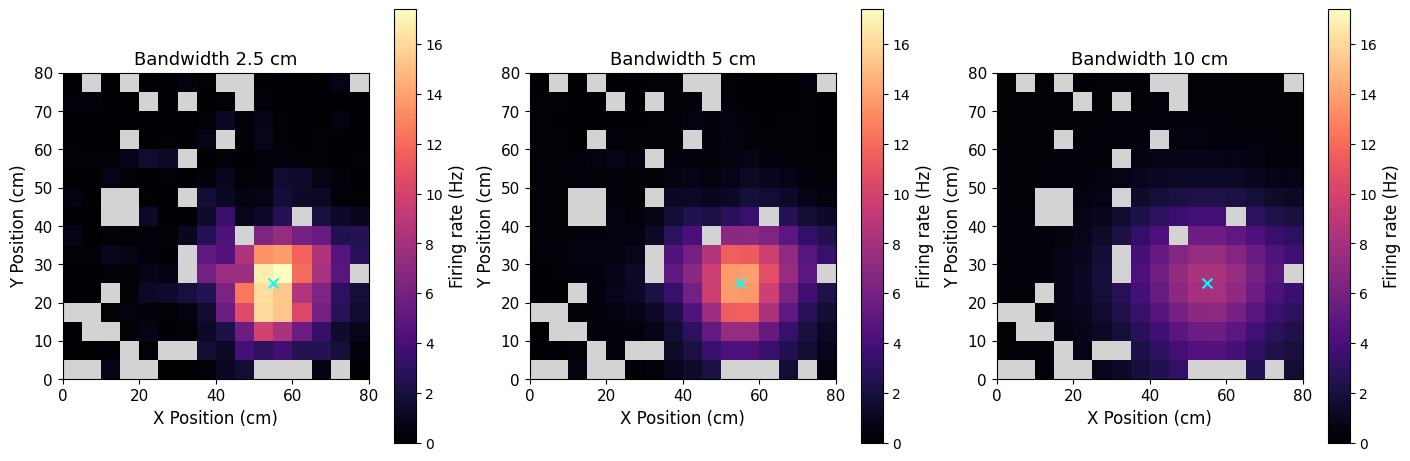

In [5]:
bandwidths = [2.5, 5.0, 10.0]
maps = []
for bandwidth in bandwidths:
    estimate = compute_spatial_rate(
        env,
        spike_times,
        times,
        positions,
        method="diffusion_kde",
        bandwidth=bandwidth,
        **settings,
    )
    maps.append(np.where(estimate.spatial_support, estimate.firing_rate, np.nan))

vmax = max(np.nanmax(rate) for rate in maps)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), layout="constrained")
for ax, bandwidth, rate in zip(axes, bandwidths, maps):
    env.plot_field(
        rate,
        ax=ax,
        cmap="magma",
        vmin=0,
        vmax=vmax,
        nan_color="lightgray",
        colorbar_label="Firing rate (Hz)",
    )
    ax.scatter(*center, marker="x", color="cyan", s=50)
    ax.set_title(f"Bandwidth {bandwidth:g} cm")
plt.show()

The cyan cross is the simulation's tuning center. Real data do not supply that
answer. Compare settings using held-out time, repeated traversals, or an
explicit validation model. For several neurons use `compute_spatial_rates()`
to share occupancy and kernel computation, as in
[04: real-data analysis](04_real_data_analysis.ipynb).

## 4. Segment candidate high-rate regions

Field segmentation groups connected bins exceeding a fraction of the peak.
It describes the chosen map; it is not a significance test or a cell-type
classifier. Both bandwidth and threshold affect the returned regions.
Here `min_size=4` requires four 5 × 5 cm bins, or 100 cm² of bin area.

Candidate regions: 1
  Region 1: 38 bins, area 950 cm², peak 13.92 Hz


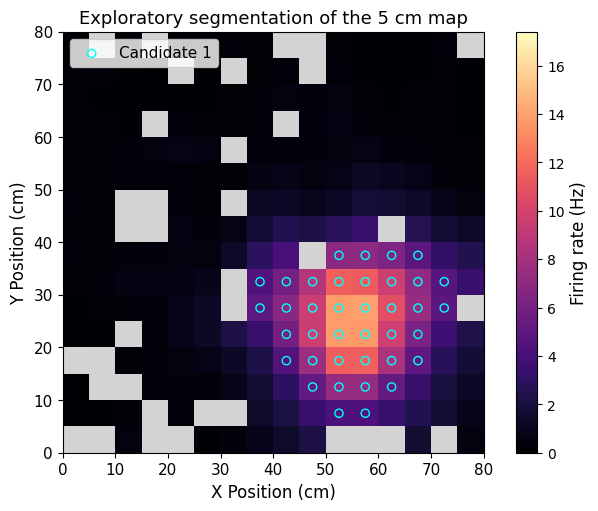

In [6]:
fields = detect_place_fields(env, supported_rate, threshold=0.3, min_size=4)
print(f"Candidate regions: {len(fields)}")
for number, bins in enumerate(fields, start=1):
    area = env.bin_sizes[bins].sum()
    peak = np.nanmax(supported_rate[bins])
    print(
        f"  Region {number}: {len(bins)} bins, area {area:.0f} cm², peak {peak:.2f} Hz"
    )

fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
env.plot_field(
    supported_rate,
    ax=ax,
    cmap="magma",
    vmin=0,
    vmax=vmax,
    nan_color="lightgray",
    colorbar_label="Firing rate (Hz)",
)
for number, bins in enumerate(fields, start=1):
    ax.scatter(
        *env.bin_centers[bins].T,
        facecolors="none",
        edgecolors="cyan",
        s=35,
        label=f"Candidate {number}",
    )
if fields:
    ax.legend(loc="upper left")
ax.set_title("Exploratory segmentation of the 5 cm map")
plt.show()

## Continue with your analysis

[03: trajectories and behavior](03_trajectories_and_behavior.ipynb) defines
movement and traversal epochs that can be passed to rate estimation.
[05: simulation and validation](05_simulation_and_validation.ipynb) develops
checks against known tuning, and
[06: position decoding](06_position_decoding.ipynb) uses population maps.

For estimator choices and interpretation, see the
[spike-field guide](https://edeno.github.io/neurospatial/user-guide/spike-field-primitives/).
For custom local statistics and filters, see the
[signal-processing guide](https://edeno.github.io/neurospatial/user-guide/signal-processing-primitives/).